In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings 
warnings.filterwarnings("ignore")

In [2]:
order = ["tile2net", "resnet18", "vit_small", "swin_tiny"]
cat = pd.CategoricalDtype(categories=order, ordered=True)
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions/evaluation_results_5seeds_epsg:26910_4.csv")
results = results.assign(model=results["model"].astype(cat)).sort_values("model")
results = results.drop(["dataset", "pred_root"], axis=1)

### Quantitative

In [8]:
order = ["tile2net", "resnet18", "vit_small", "swin_tiny"]
cat = pd.CategoricalDtype(categories=order, ordered=True)
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions/evaluation_results_5seeds_epsg:26910_4.csv")
results = results.assign(model=results["model"].astype(cat)).sort_values("model")
results = results.drop(["dataset", "pred_root"], axis=1)
results.drop("model",axis=1).groupby(["tag"]).mean().reset_index()[["tag", "avg_num_components"]]

,tag,avg_num_components
0,base,1.233102
1,grpo,1.325069
2,step,1.376374


In [9]:
order = ["tile2net", "resnet18", "vit_small", "swin_tiny"]
cat = pd.CategoricalDtype(categories=order, ordered=True)
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions_seattle/evaluation_results_5seeds_epsg:26910_4.csv")
results = results.assign(model=results["model"].astype(cat)).sort_values("model")
results = results.drop(["dataset", "pred_root"], axis=1)
results.drop("model",axis=1).groupby(["tag"]).mean().reset_index()[["tag", "avg_num_components"]]

,tag,avg_num_components
0,base,1.006099
1,grpo,1.094164
2,step,1.168433


In [10]:
order = ["tile2net", "resnet18", "vit_small", "swin_tiny"]
cat = pd.CategoricalDtype(categories=order, ordered=True)
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions_dc/evaluation_results_5seeds_epsg:26910_4.csv")
results = results.assign(model=results["model"].astype(cat)).sort_values("model")
results = results.drop(["dataset", "pred_root"], axis=1)
results.drop("model",axis=1).groupby(["tag"]).mean().reset_index()[["tag", "avg_num_components"]]

,tag,avg_num_components
0,base,1.076948
1,grpo,1.076717
2,step,1.087319


### Visualization

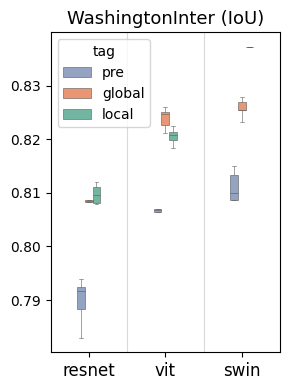

In [34]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions/evaluation_results_5seeds_epsg:26910_4.csv")
results = results.drop(["dataset", "pred_root"], axis=1)
results = results[results.model != "tile2net"]
results.tag[results.tag == 'base'] = 'pre'
results.tag[results.tag == 'grpo'] = 'global'
results.tag[results.tag == 'step'] = 'local'

tags = list(results["tag"].unique())
palette_list = sns.color_palette("Set2", n_colors=len(tags))
palette = dict(zip(tags[::-1], palette_list))

model_order = ["resnet18", "vit_small", "swin_tiny"]
pretty_model = {"resnet18": "resnet", "vit_small": "vit", "swin_tiny": "swin"}
metric = 'iou'

fig, ax = plt.subplots(figsize=(3, 4))
sns.boxplot(data=results,x="model", y=metric, hue="tag",order=model_order,palette=palette,width=0.3,linewidth=0.4,showfliers=False,ax=ax,legend=True)
ax.grid(False)
for x in range(1, len(model_order)):
    ax.axvline(x - 0.5, color="0.85", linewidth=0.8, zorder=0)
    
ax.set_title("WashingtonInter (IoU)", fontsize=13)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([pretty_model.get(m, m) for m in model_order], fontsize=12)
fig.tight_layout()
plt.savefig(f"visualizations/washingtoninter_iou.png", bbox_inches="tight", pad_inches=0.1, dpi=600)
plt.show()

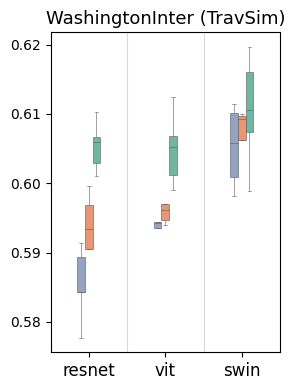

In [35]:
metric = 'traversability_similarity'
fig, ax = plt.subplots(figsize=(3, 4))
sns.boxplot(data=results,x="model", y=metric, hue="tag",order=model_order,palette=palette,width=0.3,linewidth=0.4,showfliers=False,ax=ax,legend=False)
ax.grid(False)
for x in range(1, len(model_order)):
    ax.axvline(x - 0.5, color="0.85", linewidth=0.8, zorder=0)
    
ax.set_title("WashingtonInter (TravSim)", fontsize=13)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([pretty_model.get(m, m) for m in model_order], fontsize=12)
fig.tight_layout()
plt.savefig("visualizations/washingtoninter_travsim.png", bbox_inches="tight", pad_inches=0.1, dpi=600)
plt.show()

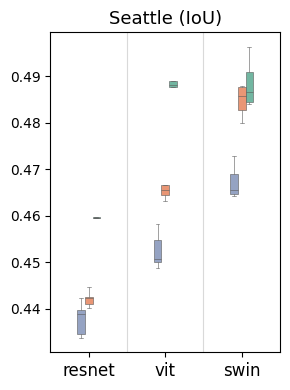

In [44]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions_seattle/evaluation_results_5seeds_epsg:26910_4.csv")
results = results.drop(["dataset", "pred_root"], axis=1)
results = results[results.model != "tile2net"]
results.tag[results.tag == 'base'] = 'pre'
results.tag[results.tag == 'grpo'] = 'global'
results.tag[results.tag == 'step'] = 'local'

tags = list(results["tag"].unique())
palette_list = sns.color_palette("Set2", n_colors=len(tags))
palette = dict(zip(tags[::-1], palette_list))

model_order = ["resnet18", "vit_small", "swin_tiny"]
pretty_model = {"resnet18": "resnet", "vit_small": "vit", "swin_tiny": "swin"}

metric = 'iou'
fig, ax = plt.subplots(figsize=(3, 4))
sns.boxplot(data=results,x="model", y=metric, hue="tag",order=model_order,palette=palette,width=0.3,linewidth=0.4,showfliers=False,ax=ax,legend=False)
ax.grid(False)
for x in range(1, len(model_order)):
    ax.axvline(x - 0.5, color="0.85", linewidth=0.8, zorder=0)
    
ax.set_title("Seattle (IoU)", fontsize=13)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([pretty_model.get(m, m) for m in model_order], fontsize=12)
fig.tight_layout()
plt.savefig("visualizations/seattle_iou.png", bbox_inches="tight", pad_inches=0.1, dpi=600)
plt.show()

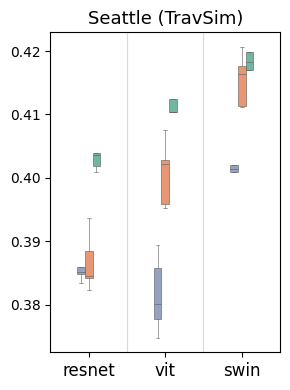

In [45]:
metric = 'traversability_similarity'
fig, ax = plt.subplots(figsize=(3, 4))
sns.boxplot(data=results,x="model", y=metric, hue="tag",order=model_order,palette=palette,width=0.3,linewidth=0.4,showfliers=False,ax=ax,legend=False)
ax.grid(False)
for x in range(1, len(model_order)):
    ax.axvline(x - 0.5, color="0.85", linewidth=0.8, zorder=0)
    
ax.set_title("Seattle (TravSim)", fontsize=13)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([pretty_model.get(m, m) for m in model_order], fontsize=12)
fig.tight_layout()
plt.savefig("visualizations/seattle_travsim.png", bbox_inches="tight", pad_inches=0.1, dpi=600)
plt.show()

### PathwayBench

In [2]:
results = pd.read_csv("/data/models/bin/2026_pathway_generation/predictions_seattle/evaluation_results_5seeds.csv")
results = results.drop(["dataset", "pred_root"], axis=1)
results = results[results.model != "tile2net"]

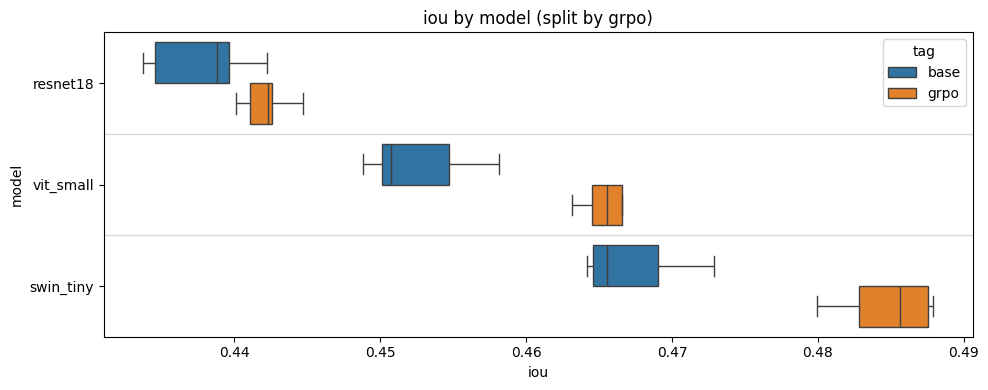

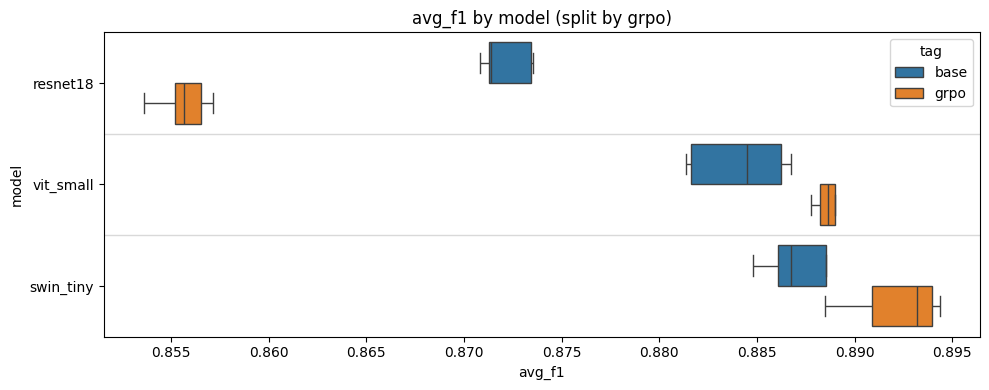

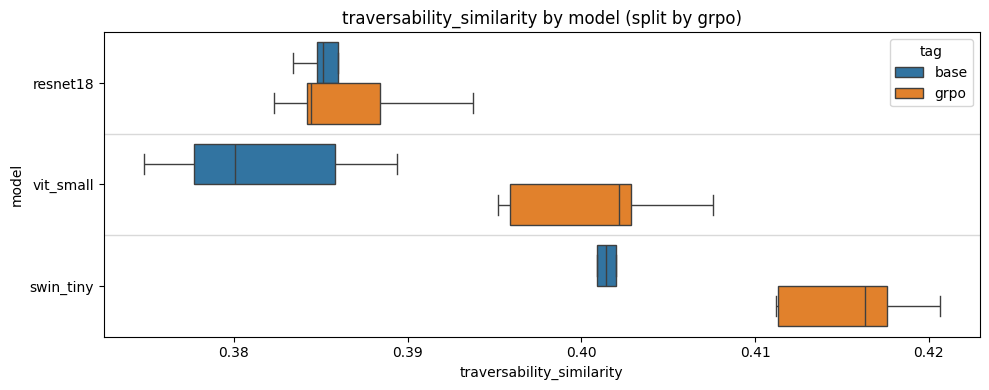

In [7]:
for metric in ["iou", "avg_f1", "traversability_similarity"]:
    plt.figure(figsize=(10, 4))
    model_order = ["resnet18", "vit_small", "swin_tiny"]
    ax = sns.boxplot(
        y="model", x=metric, hue="tag",
        data=results,
        order=model_order,
        showbox=True,
        showfliers=False
    )
    n_models = results["model"].nunique()
    for y in range(1, n_models):
        ax.axhline(y - 0.5, color="0.85", linewidth=1, zorder=0)
    ax.set_title(f"{metric} by model (split by grpo)")
    plt.tight_layout()
    plt.show()

In [5]:
results.groupby(["model", "tag"]).mean().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]]

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.437797,0.872079,0.385890
1,resnet18,grpo,0.442145,0.855619,0.386631
2,swin_tiny,base,0.467256,0.887781,0.400705
3,swin_tiny,grpo,0.484781,0.892170,0.415410
4,vit_small,base,0.452502,0.884082,0.381567
5,vit_small,grpo,0.466169,0.888916,0.400737


In [8]:
results.groupby(["model", "tag"]).std().reset_index()[["model", "tag", "iou", "avg_f1", "traversability_similarity"]]

,model,tag,iou,avg_f1,traversability_similarity
0,resnet18,base,0.003582,0.001293,0.002542
1,resnet18,grpo,0.001738,0.001365,0.004549
2,swin_tiny,base,0.003683,0.003100,0.003559
3,swin_tiny,grpo,0.003368,0.002471,0.004109
4,vit_small,base,0.003849,0.002508,0.005967
5,vit_small,grpo,0.003027,0.001241,0.005180
